In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="moD8XngJfumsdxMbd9iJ")
project = rf.workspace("roboflow-100").project("vehicles-q0x2v")
version = project.version(1)
dataset = version.download("yolov11")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 31.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 139.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 7.0 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to vehicles-1 in yolov11:: 100%|██████████| 8128/8128 [00:01<00:00, 6364.04it/s]


In [ ]:
import glob, os

ROOT = '/content/vehicles-1'

print('Number of images per train, test and validation: ')
for folder in os.listdir(ROOT):
  if os.path.isdir(f'{ROOT}/{folder}'):
    print(
        f'{folder}: {len(os.listdir(os.path.join(ROOT, folder, 'images')))}'
    )

Number of images per train, test and validation: 
valid: 966
test: 458
train: 2634


In [ ]:
# An example of a label file associated with an image
# cls_id cx cy width height
train_annotations = glob.glob(f'{ROOT}/train/labels/*.txt')
print(open(train_annotations[0]).read())

10 0.34765625 0.378125 0.0421875 0.05625
9 0.55546875 0.43203125 0.0515625 0.09375
4 0.36484375 0.43359375 0.0421875 0.05
4 0.5125 0.49375 0.053125 0.07109375
11 0.64453125 0.54921875 0.1421875 0.23515625
4 0.75859375 0.584375 0.0921875 0.13515625
4 0.67890625 0.86875 0.1453125 0.24140625


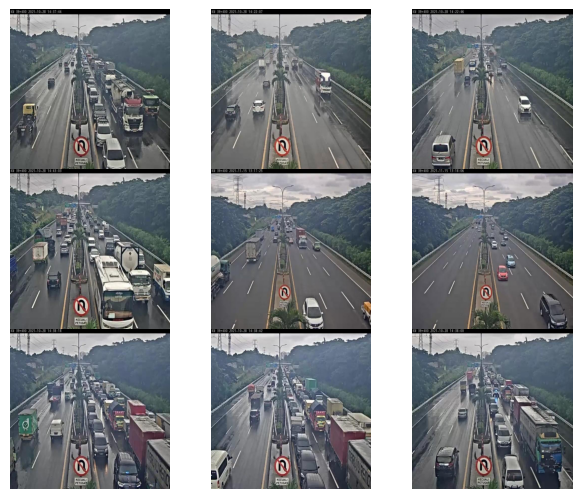

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import random

train_images = glob.glob(f'{ROOT}/train/images/*.jpg')
figure, axes = plt.subplots(3, 3)

for ax, name in zip(axes.ravel(), random.sample(train_images, 9)):
  im = Image.open(name)
  ax.imshow(im)
  ax.set_axis_off()

plt.tight_layout(pad=0)
plt.show()

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 52.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 11.5 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

model = YOLO('yolo11n.pt', task="detect", verbose=True)

train_results = model.train(
    data=f'{dataset.location}/data.yaml',
    epochs=10,
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    translate=0.0,
    scale=0.0,
    fliplr=0.0,
    mosaic=0.0,
    erasing=0.0,
    auto_augment=None,
    )

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=None, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/vehicles-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.0, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=

In [ ]:
import pandas as pd

CLASSES = train_results.names
print(CLASSES)

# Training and validation results
df = pd.read_csv('/content/runs/detect/train/results.csv')
print(df)

{0: 'big bus', 1: 'big truck', 2: 'bus-l-', 3: 'bus-s-', 4: 'car', 5: 'mid truck', 6: 'small bus', 7: 'small truck', 8: 'truck-l-', 9: 'truck-m-', 10: 'truck-s-', 11: 'truck-xl-'}
   epoch      time  train/box_loss  train/cls_loss  train/dfl_loss  \
0      1   43.6641         1.37699         1.82175         1.15709   
1      2   80.9187         1.20334         0.98860         1.06452   
2      3  115.2830         1.13467         0.82092         1.03721   
3      4  149.9890         1.06320         0.71407         1.01007   
4      5  184.1730         1.00478         0.62770         0.98877   
5      6  218.6190         0.95020         0.57080         0.96809   
6      7  253.2200         0.89459         0.52217         0.94852   
7      8  287.8340         0.83310         0.47838         0.92849   
8      9  321.9620         0.76881         0.44107         0.90844   
9     10  356.1310         0.71237         0.41181         0.89244   

   metrics/precision(B)  metrics/recall(B)  metri

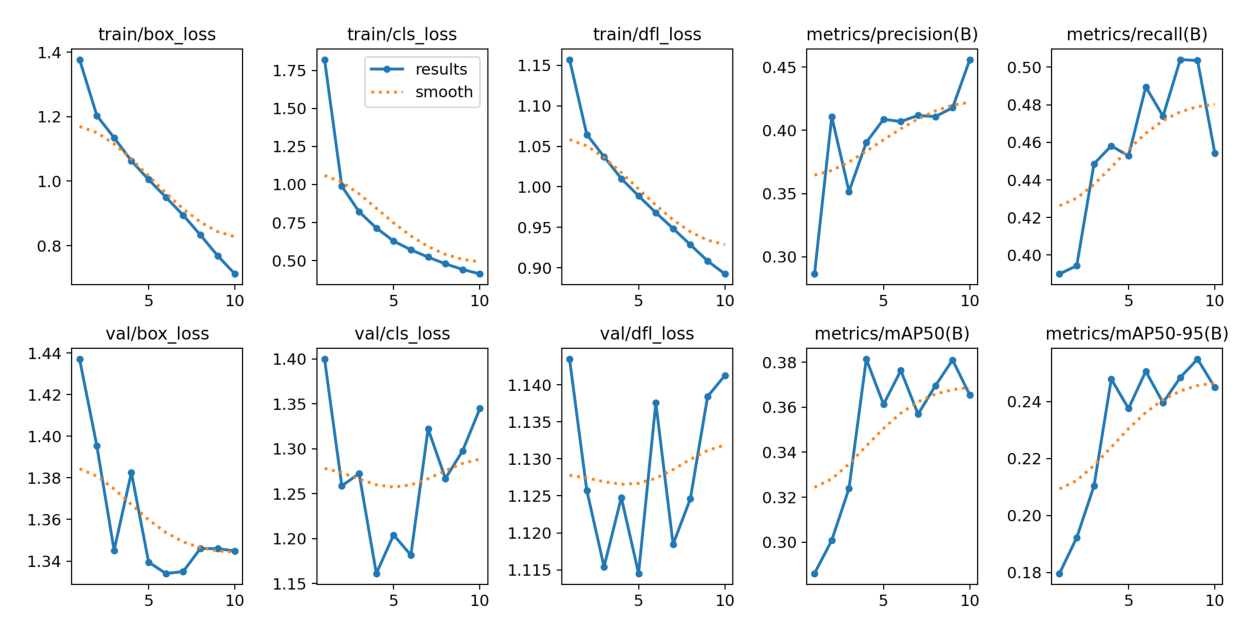

In [ ]:
results_image = Image.open('/content/runs/detect/train/results.png')

plt.figure(figsize=(20,8))
fig = plt.imshow(results_image)
fig.axes.set_axis_off()

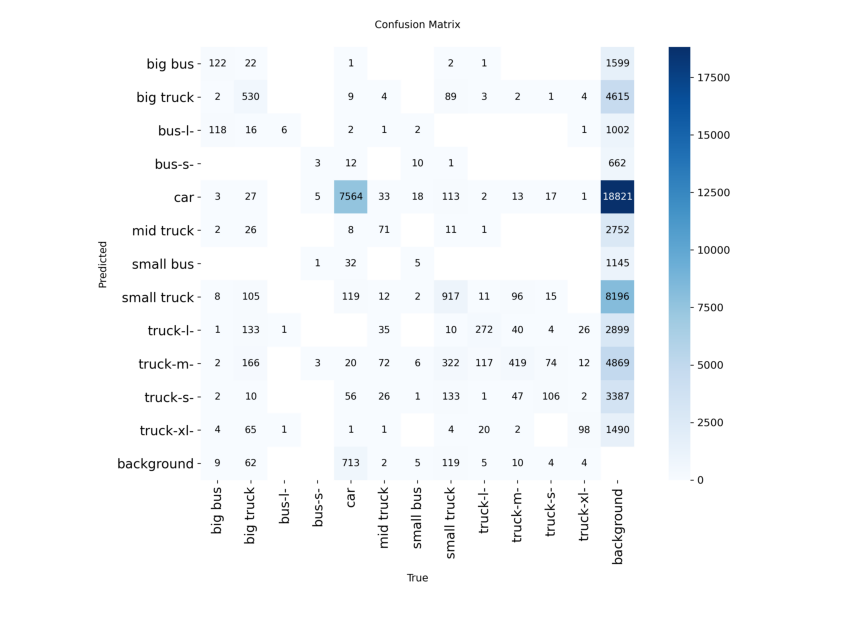

In [ ]:
confusion_matrix = Image.open('/content/runs/detect/train/confusion_matrix.png')

plt.figure(figsize=(20,8))
fig = plt.imshow(confusion_matrix)
fig.axes.set_axis_off()

In [ ]:
true_labels = Image.open('/content/runs/detect/train/val_batch0_labels.jpg')
pred_labels = Image.open('/content/runs/detect/train/val_batch0_pred.jpg')

fig, axes = plt.subplots(2,1)
fig.set_figwidth(20)
fig.set_figheight(20)

axes[0].imshow(true_labels)
axes[0].set_axis_off()
axes[0].set_title('True Labels')

axes[1].imshow(pred_labels)
axes[1].set_axis_off()
axes[1].set_title('Predicted Labels')

plt.tight_layout(pad=2)


In [ ]:
validation_results = model.val()

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,599,724 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1349.6±394.3 MB/s, size: 57.0 KB)
val: Scanning /content/vehicles-1/valid/labels.cache... 966 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 966/966 238.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 61/61 3.5it/s 17.4s
                   all        966      13450      0.418      0.506      0.381      0.255
               big bus        210        273      0.728      0.473      0.629      0.439
             big truck        404       1162       0.67      0.458      0.544      0.331
                bus-l-          8          8     0.0271      0.504     0.0289     0.0103
                bus-s-         12         12      0.173       0.28     0.0953     0.0672
                   car        927       

In [ ]:
results = model.predict(source=f"{ROOT}/test/images")


image 1/458 /content/vehicles-1/test/images/adit_mp4-1002_jpg.rf.9effa5a5f1b95f251194f16d122d5ef0.jpg: 640x640 8 cars, 1 truck-m-, 10.6ms
image 2/458 /content/vehicles-1/test/images/adit_mp4-1008_jpg.rf.78a4956560a79d1d8f3611b00baa8785.jpg: 640x640 10 cars, 1 truck-m-, 13.7ms
image 3/458 /content/vehicles-1/test/images/adit_mp4-1022_jpg.rf.d0e360f994683fc8b1bc9ebfa684a1ec.jpg: 640x640 3 cars, 1 truck-m-, 11.6ms
image 4/458 /content/vehicles-1/test/images/adit_mp4-1028_jpg.rf.4406265d3ebaeb90517f5ea54c0f6e2d.jpg: 640x640 7 cars, 1 truck-m-, 11.1ms
image 5/458 /content/vehicles-1/test/images/adit_mp4-1035_jpg.rf.ecbd9a641b73bd1c44a6dd74c11231bd.jpg: 640x640 1 car, 1 truck-m-, 10.6ms
image 6/458 /content/vehicles-1/test/images/adit_mp4-1049_jpg.rf.fde8c661e90c6d526aba435b4b30893a.jpg: 640x640 2 big trucks, 2 cars, 1 truck-l-, 2 truck-m-s, 1 truck-s-, 10.6ms
image 7/458 /content/vehicles-1/test/images/adit_mp4-1055_jpg.rf.59812e37fed36591269646fc43d47389.jpg: 640x640 2 big trucks, 5 cars,

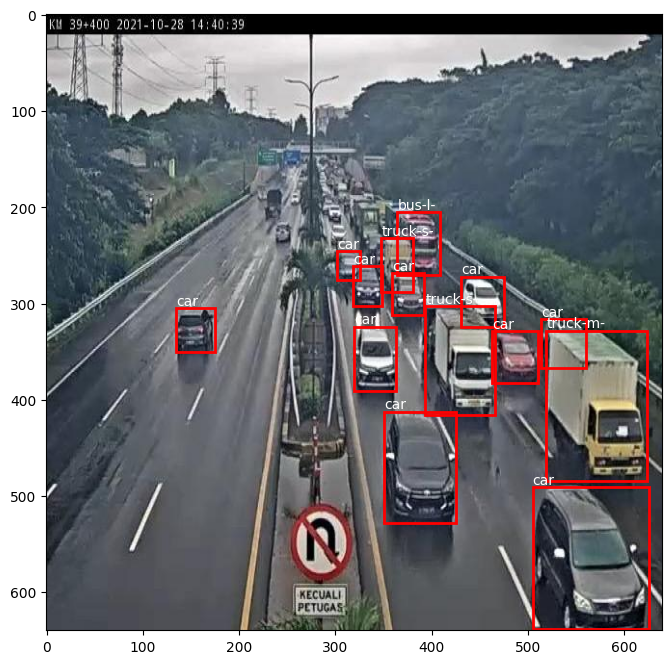

In [ ]:
import matplotlib.patches as patches

random_result = random.sample(results, 1)[0]
random_result_img = Image.open(random_result.path)

fig, ax = plt.subplots(1,1,figsize=(20,8))
ax.imshow(random_result_img)
boxes = random_result.boxes

for box in boxes:
  box_cls = box.cls[0].item()

  xmin, ymin, _, _ = box.xyxy[0].tolist()
  _, _, w, h = box.xywh[0].tolist()

  ax.add_patch(patches.Rectangle((xmin,ymin), w, h, fill=False, edgecolor='red', linewidth=2))
  ax.text(xmin, ymin - 3, CLASSES[box_cls], color="white")

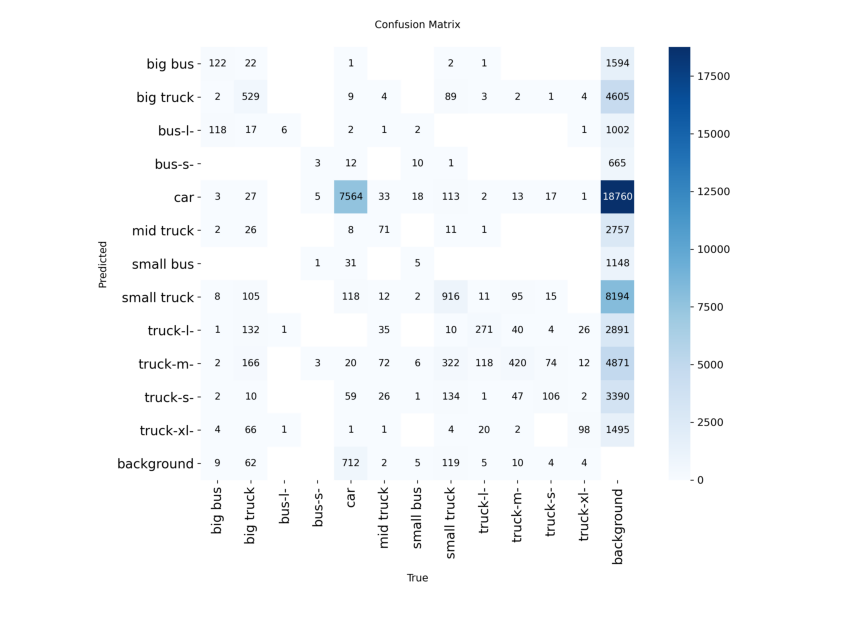

In [ ]:
pred_confusion_matrix = Image.open('/content/runs/detect/val/confusion_matrix.png')

plt.figure(figsize=(20,8))
fig = plt.imshow(pred_confusion_matrix)
fig.axes.set_axis_off()

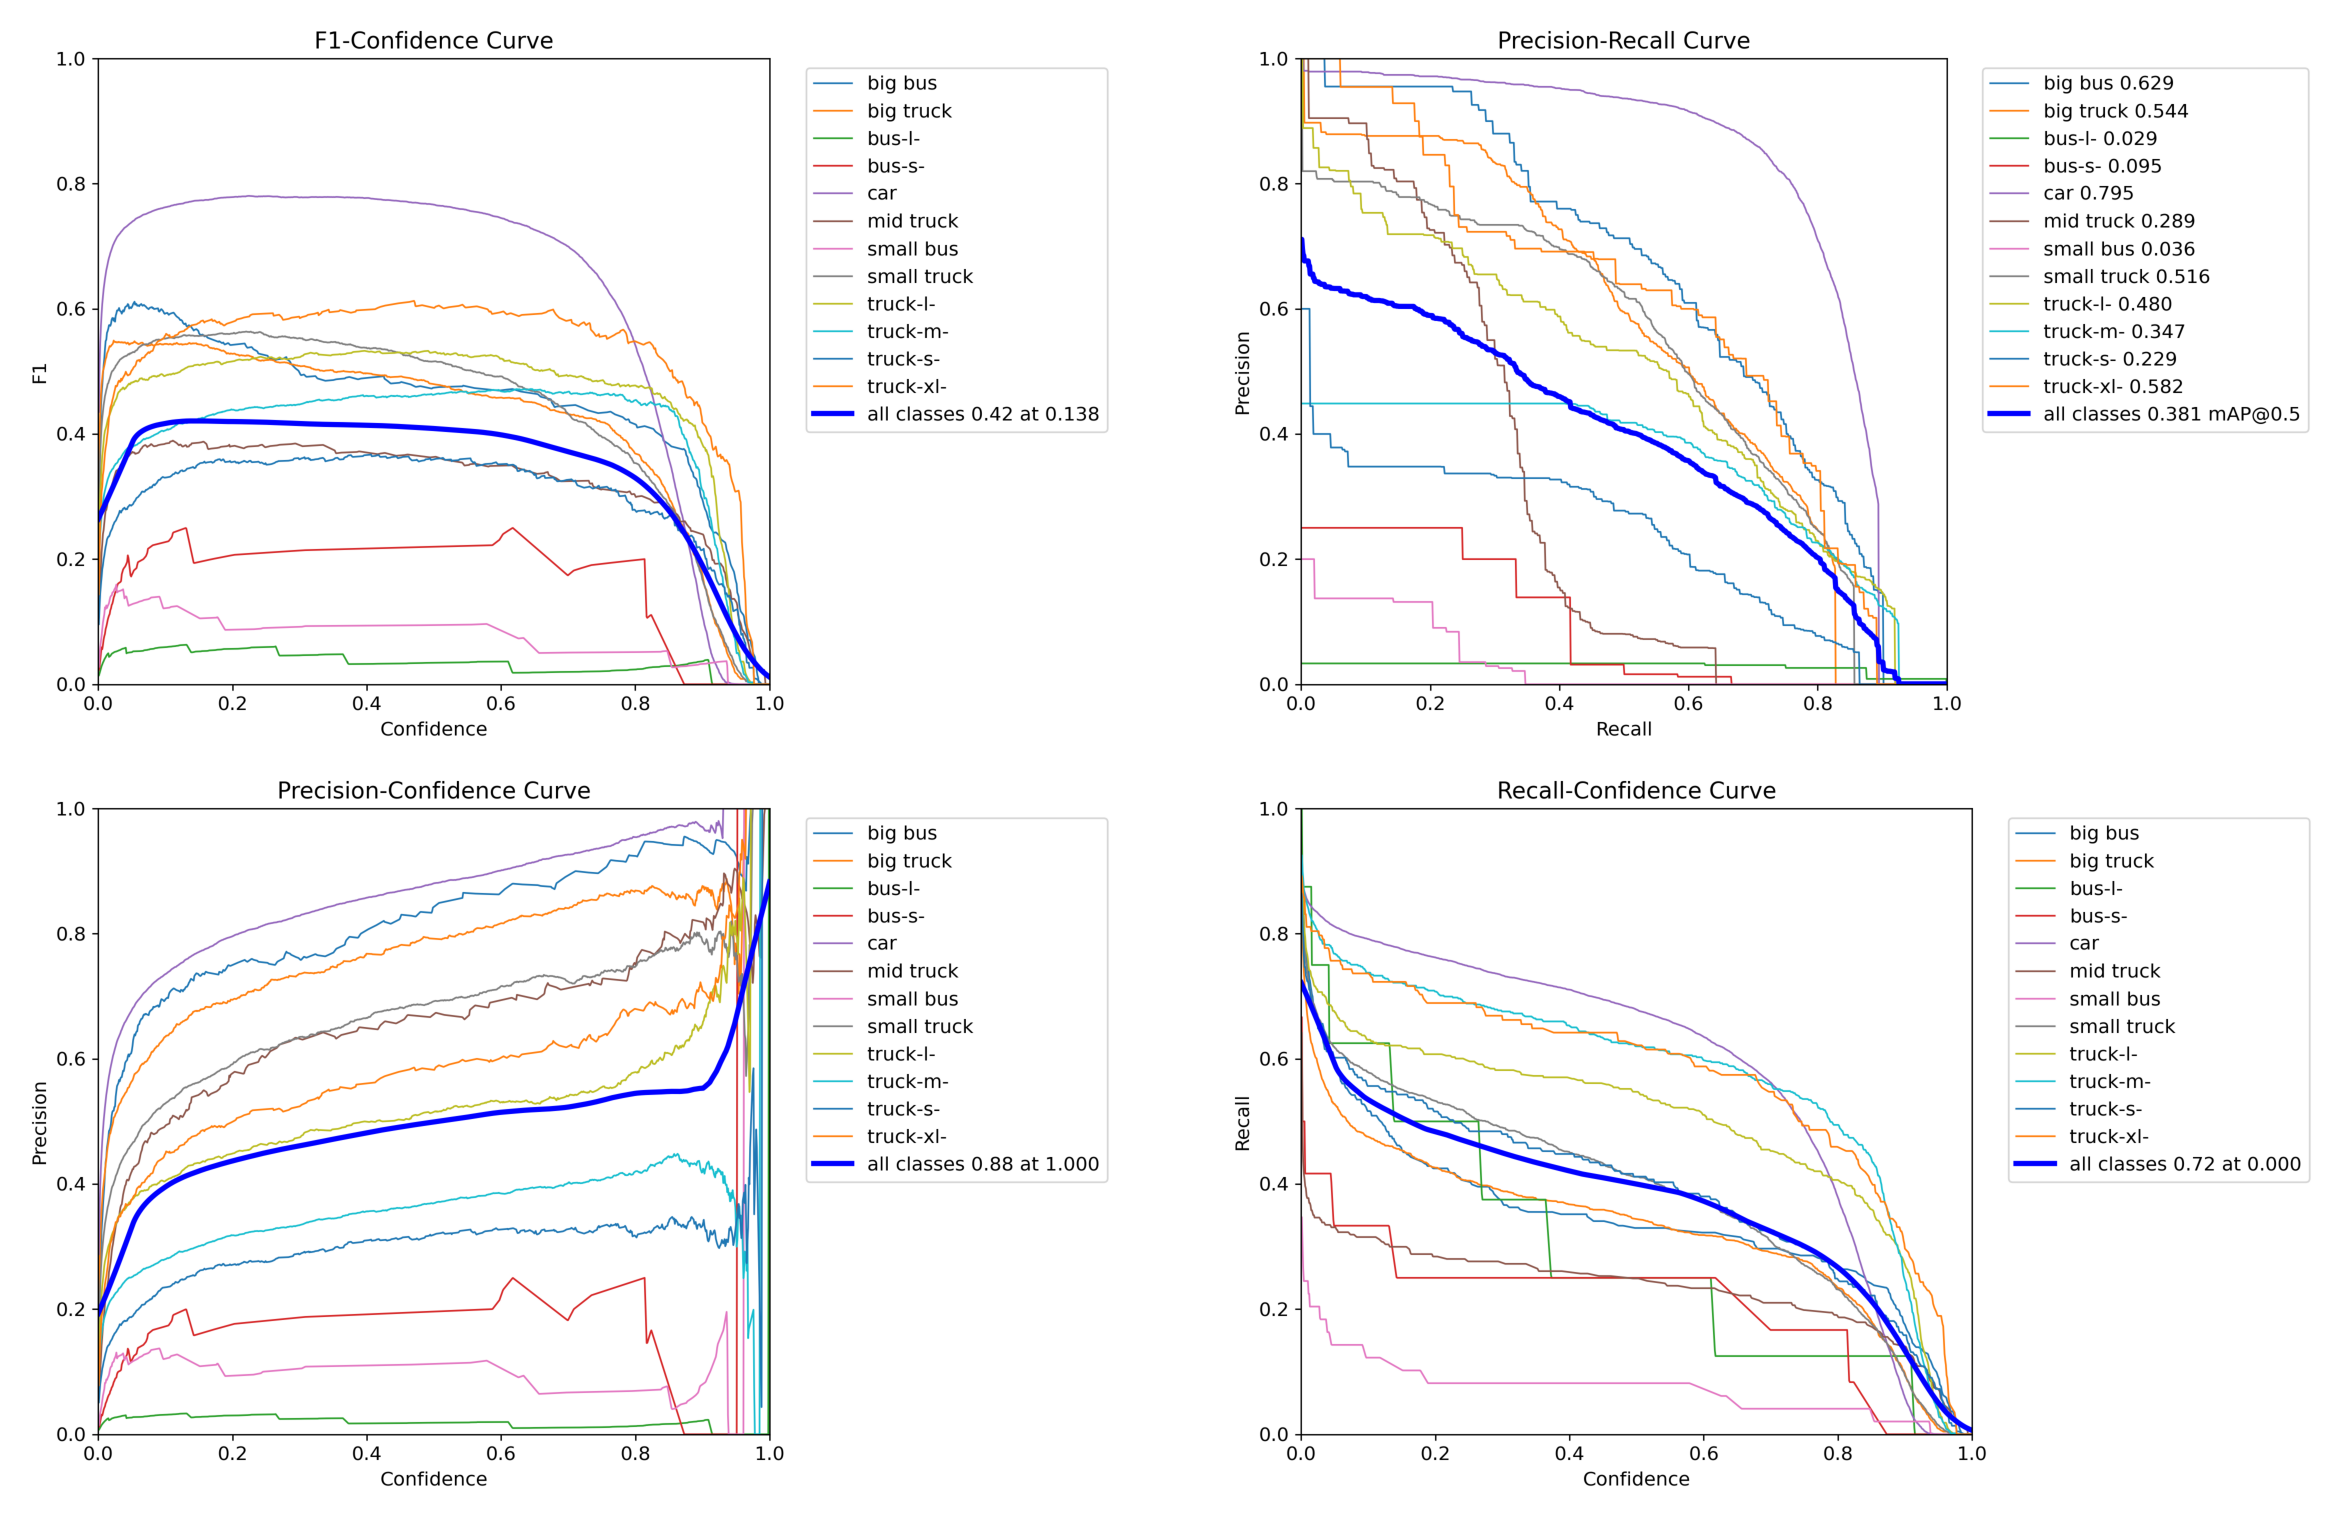

In [ ]:
ROOT_PATH = "/content/runs/detect/val"
pred_curves = [f'{ROOT_PATH}/BoxF1_curve.png', f'{ROOT_PATH}/BoxPR_curve.png', f'{ROOT_PATH}/BoxP_curve.png', f'{ROOT_PATH}/BoxR_curve.png']

fig, axes = plt.subplots(2,2, figsize=(25,15))

for ax, path in zip(axes.ravel(), pred_curves):
  im = Image.open(path)
  ax.set_axis_off()
  ax.imshow(im)

plt.tight_layout(pad=0)

In [ ]:
from google.colab import files

files.download('/content/runs/detect/train/weights/best.pt')